# Modeling on 20-second windows: naive baseline vs. tuned ridge vs. tuned gradient boosting

Same pipeline as `modeling.ipynb`, but trained on `data/bp_training_dataset_20s.csv`
instead of `data/ppg_features.csv`. This file has the **same 14 PPG features and the
same columns**, but each row summarizes a **20-second window** instead of a 5-second
one, so there are fewer, longer windows (fewer, more heartbeats averaged into each
row's features).

**Purpose:** directly compare whether longer windows produce lower MAE/RMSE than the
original 5-second windows, with everything else (split logic, CV grids, random seeds,
model code) held identical.

Pipeline, using the shared code in `../src/`:

1. Load `data/bp_training_dataset_20s.csv`.
2. Split into train/test **by whole recording** (`src/data_split.py`).
3. Compute the **naive baseline** (`src/baseline.py`).
4. **Tune hyperparameters** using grouped K-fold cross-validation *within the train
   set only* (`src/cross_validation.py`) — same grids as `modeling.ipynb`.
5. Refit the winning hyperparameters on the full train set, evaluate once on the
   held-out test recordings.
6. Explain predictions with ridge coefficients and GBM permutation importance.

Run this notebook from `notebooks/`.

## Setup

In [1]:
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path('..').resolve()))

from src.data_split import grouped_train_test_split, split_summary
from src.baseline import compute_naive_baseline, evaluate_naive_baseline
from src.models import FEATURE_COLUMNS, fit_gbm, fit_ridge, evaluate_model
from src.cross_validation import ridge_alpha_search, gbm_param_search, RIDGE_ALPHA_GRID, GBM_PARAM_GRID
from src.importance import importance_report
from src.baseline import evaluate_predictions

results_dir = Path('../results')
graphs_dir = results_dir / 'graphs'
graphs_dir.mkdir(parents=True, exist_ok=True)

TARGET_COLS = ('sbp', 'dbp')
RANDOM_STATE = 42
N_SPLITS = 5

## 1. Load the feature table

One row per usable 20-second window: same 14 PPG features, SBP/DBP labels, and source
IDs (`file`, `record_index`, `start_sample`) as `ppg_features.csv`.

In [2]:
df = pd.read_csv('../data/bp_training_dataset_20s.csv')
assert set(FEATURE_COLUMNS).issubset(df.columns)
assert set(TARGET_COLS).issubset(df.columns)
print(f'Loaded {len(df):,} rows, {df["file"].nunique()} source file(s), '
      f'{df[["file", "record_index"]].drop_duplicates().shape[0]:,} recordings.')
df.head()

Loaded 128,460 rows, 4 source file(s), 10,161 recordings.


,file,record_index,start_sample,inband_power_ratio,sbp,dbp,heart_rate_bpm,beat_interval_std_ms,pulse_height,rise_time_s,...,rise_fall_ratio,pulse_width_s,max_upslope,ppg_std,ppg_min,ppg_max,ppg_range,ppg_skewness,ppg_kurtosis,n_beats
0,Part_1.mat,0,0,0.987167,123.404629,68.088681,123.253903,6.079474,1.851173,0.140513,...,0.406459,0.173744,22.724423,0.613443,-1.029505,1.243450,2.272955,0.516770,-1.134660,39
1,Part_1.mat,0,2500,0.975568,126.603918,69.358628,123.102175,6.785278,1.891894,0.141744,...,0.409934,0.178872,23.010712,0.623570,-1.198713,1.419277,2.617990,0.487601,-1.110464,39
2,Part_1.mat,0,5000,0.961351,127.971553,69.993601,122.384937,7.458322,1.819376,0.146947,...,0.444195,0.175579,21.922589,0.627148,-1.477289,1.711071,3.188360,0.486468,-0.875359,38
3,Part_1.mat,0,7500,0.987756,127.873865,69.358628,119.396732,45.212211,1.886251,0.139892,...,0.389134,0.175135,23.099713,0.625150,-1.061084,1.329514,2.390597,0.549538,-1.071413,37
4,Part_1.mat,0,10000,0.975114,125.968945,68.821343,122.100122,9.101648,1.825130,0.146667,...,0.437251,0.172718,22.156398,0.633794,-1.430140,1.974988,3.405128,0.510143,-0.736210,39


## 2. Split by recording

Same 80/20 grouped split as `modeling.ipynb`, same `random_state`.

In [3]:
train_df, test_df = grouped_train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
split_summary(train_df, test_df)

,split,rows,recordings
0,train,103033,8128
1,test,25427,2033


## 3. Naive baseline

In [4]:
baseline_values = compute_naive_baseline(train_df, TARGET_COLS)
baseline_results = evaluate_naive_baseline(baseline_values, test_df, TARGET_COLS)
print('Naive baseline (train-set mean):', baseline_values)
baseline_results.round(3)

Naive baseline (train-set mean): {'sbp': 129.06664809218012, 'dbp': 67.75895857862686}


,target,predicted_value,mae,rmse
0,sbp,129.067,17.840,22.024
1,dbp,67.759,8.729,11.475


## 4. Hyperparameter tuning (grouped K-fold CV, train set only)

Same grids as `modeling.ipynb`:

- **Ridge**: `alpha` in `[0.001, 0.01, 0.1, 1, 10, 100, 1000]`.
- **Gradient boosting**: `learning_rate` x `max_leaf_nodes` x `min_samples_leaf`
  (45 combinations).

In [5]:
ridge_cv_results = {}
ridge_best_alpha = {}

for target in TARGET_COLS:
    results, search = ridge_alpha_search(train_df, target, n_splits=N_SPLITS, random_state=RANDOM_STATE)
    ridge_cv_results[target] = results
    ridge_best_alpha[target] = search.best_params_['ridge__alpha']
    print(f'--- Ridge CV for {target.upper()} ---')
    display(results)
    print(f'Best alpha: {ridge_best_alpha[target]}\n')

--- Ridge CV for SBP ---


,params,rank,mean_mae,std_mae
0,{'ridge__alpha': 0.001},1,17.331737,0.321384
1,{'ridge__alpha': 0.01},2,17.331737,0.321385
2,{'ridge__alpha': 0.1},3,17.331742,0.321387
3,{'ridge__alpha': 1},4,17.331786,0.321411
4,{'ridge__alpha': 10},5,17.332247,0.321649
5,{'ridge__alpha': 100},6,17.337739,0.323658
6,{'ridge__alpha': 1000},7,17.394646,0.328167


Best alpha: 0.001



--- Ridge CV for DBP ---


,params,rank,mean_mae,std_mae
0,{'ridge__alpha': 0.001},1,8.440789,0.105965
1,{'ridge__alpha': 0.01},2,8.440789,0.105965
2,{'ridge__alpha': 0.1},3,8.440792,0.105966
3,{'ridge__alpha': 1},4,8.440827,0.105973
4,{'ridge__alpha': 10},5,8.441172,0.106042
5,{'ridge__alpha': 100},6,8.444623,0.106648
6,{'ridge__alpha': 1000},7,8.471485,0.111131


Best alpha: 0.001



In [6]:
gbm_cv_results = {}
gbm_best_params = {}

for target in TARGET_COLS:
    results, search = gbm_param_search(train_df, target, n_splits=N_SPLITS, random_state=RANDOM_STATE)
    gbm_cv_results[target] = results
    gbm_best_params[target] = search.best_params_
    print(f'--- Gradient boosting CV for {target.upper()} (top 5 of {len(results)} combos) ---')
    display(results.head())
    print(f'Best params: {gbm_best_params[target]}\n')

/opt/anaconda3/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


--- Gradient boosting CV for SBP (top 5 of 48 combos) ---


,params,rank,mean_mae,std_mae
0,"{'learning_rate': 0.02, 'max_leaf_nodes': 1000...",1,13.774400,0.171296
1,"{'learning_rate': 0.02, 'max_leaf_nodes': 1000...",2,13.787087,0.150425
2,"{'learning_rate': 0.05, 'max_leaf_nodes': 1000...",3,13.787302,0.159072
3,"{'learning_rate': 0.02, 'max_leaf_nodes': 1000...",4,13.810957,0.143705
4,"{'learning_rate': 0.05, 'max_leaf_nodes': 1000...",5,13.811865,0.150419


Best params: {'learning_rate': 0.02, 'max_leaf_nodes': 1000, 'min_samples_leaf': 5}



/opt/anaconda3/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


--- Gradient boosting CV for DBP (top 5 of 48 combos) ---


,params,rank,mean_mae,std_mae
0,"{'learning_rate': 0.02, 'max_leaf_nodes': 1000...",1,7.136915,0.163113
1,"{'learning_rate': 0.05, 'max_leaf_nodes': 1000...",2,7.149231,0.172941
2,"{'learning_rate': 0.02, 'max_leaf_nodes': 1000...",3,7.159758,0.154238
3,"{'learning_rate': 0.02, 'max_leaf_nodes': 1000...",4,7.164774,0.162882
4,"{'learning_rate': 0.05, 'max_leaf_nodes': 1000...",5,7.167769,0.168673


Best params: {'learning_rate': 0.02, 'max_leaf_nodes': 1000, 'min_samples_leaf': 5}



## 5. Refit with the winning hyperparameters, evaluate once on the test set

In [7]:
rows = []
fitted_models = {}

for target in TARGET_COLS:
    import numpy as np
    constant_pred = np.full(len(test_df), baseline_values[target])
    rows.append({'target': target, 'model': 'naive_baseline',
                 **evaluate_predictions(test_df[target], constant_pred)})

    ridge_model = fit_ridge(train_df, target, FEATURE_COLUMNS, alpha=ridge_best_alpha[target])
    fitted_models[(target, 'ridge')] = ridge_model
    rows.append({'target': target, 'model': 'ridge (tuned)',
                 **evaluate_model(ridge_model, test_df, target, FEATURE_COLUMNS)})

    gbm_model = fit_gbm(train_df, target, FEATURE_COLUMNS, random_state=RANDOM_STATE, **gbm_best_params[target])
    fitted_models[(target, 'gbm')] = gbm_model
    rows.append({'target': target, 'model': 'gbm (tuned)',
                 **evaluate_model(gbm_model, test_df, target, FEATURE_COLUMNS)})

results = pd.DataFrame(rows)[['target', 'model', 'mae', 'rmse']]
results.round(3)

,target,model,mae,rmse
0,sbp,naive_baseline,17.840,22.024
1,sbp,ridge (tuned),16.752,21.033
2,sbp,gbm (tuned),13.300,18.064
3,dbp,naive_baseline,8.729,11.475
4,dbp,ridge (tuned),8.289,11.053
5,dbp,gbm (tuned),7.033,10.102


## 6. Compare the three models

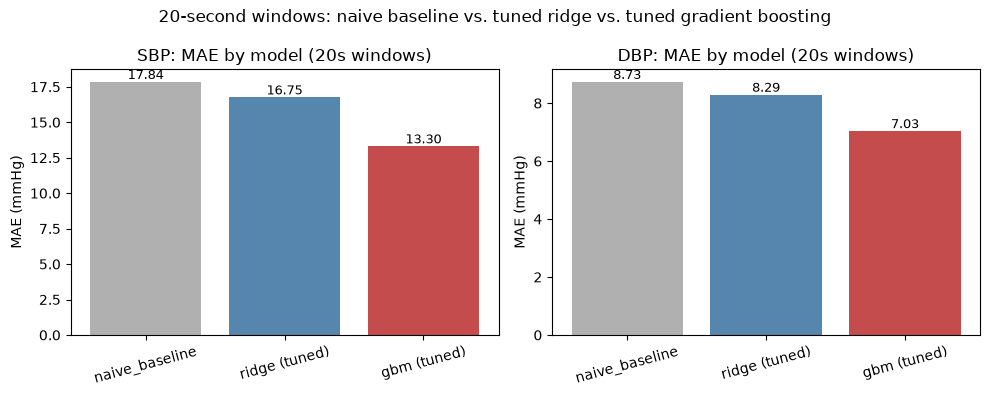

In [8]:
import matplotlib.pyplot as plt

model_order = ['naive_baseline', 'ridge (tuned)', 'gbm (tuned)']
colors = {'naive_baseline': '#b0b0b0', 'ridge (tuned)': '#5686ad', 'gbm (tuned)': '#c44c4c'}

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
for ax, target in zip(axes, TARGET_COLS):
    subset = results[results['target'] == target].set_index('model').loc[model_order]
    ax.bar(model_order, subset['mae'], color=[colors[m] for m in model_order])
    ax.set_title(f'{target.upper()}: MAE by model (20s windows)')
    ax.set_ylabel('MAE (mmHg)')
    ax.tick_params(axis='x', rotation=15)
    for i, value in enumerate(subset['mae']):
        ax.text(i, value, f'{value:.2f}', ha='center', va='bottom', fontsize=9)
fig.suptitle('20-second windows: naive baseline vs. tuned ridge vs. tuned gradient boosting')
fig.tight_layout()
fig.savefig(graphs_dir / 'model_comparison_20s.png', dpi=150)
plt.show()
plt.close(fig)

## 7. Feature importance

In [9]:
importance = importance_report(fitted_models, test_df, target_cols=TARGET_COLS)
for target in TARGET_COLS:
    print(f'--- {target.upper()} ---')
    display(importance[importance['target'] == target].drop(columns='target').round(3))

--- SBP ---


,feature,coefficient,abs_coefficient,importance_mean,importance_std
0,pulse_height,-24.996,24.996,2.278,0.038
1,max_upslope,12.141,12.141,3.268,0.033
2,ppg_std,11.402,11.402,2.697,0.050
3,heart_rate_bpm,-6.524,6.524,1.046,0.017
4,ppg_kurtosis,-5.635,5.635,1.072,0.020
5,ppg_min,-2.907,2.907,0.260,0.009
6,rise_fall_ratio,-2.009,2.009,0.908,0.015
7,ppg_range,1.584,1.584,0.149,0.010
8,pulse_width_s,-1.514,1.514,2.363,0.029
9,fall_time_s,-0.999,0.999,1.476,0.018


--- DBP ---


,feature,coefficient,abs_coefficient,importance_mean,importance_std
14,pulse_height,-9.452,9.452,1.030,0.012
15,max_upslope,6.819,6.819,1.790,0.022
16,ppg_std,2.673,2.673,0.541,0.010
17,pulse_width_s,1.240,1.240,1.051,0.018
18,ppg_min,-1.067,1.067,0.250,0.010
19,ppg_kurtosis,-0.988,0.988,0.593,0.009
20,fall_time_s,-0.958,0.958,0.524,0.009
21,beat_interval_std_ms,0.899,0.899,0.483,0.012
22,rise_time_s,0.588,0.588,0.767,0.014
23,ppg_range,0.484,0.484,0.232,0.005


## 8. Visualize feature importance

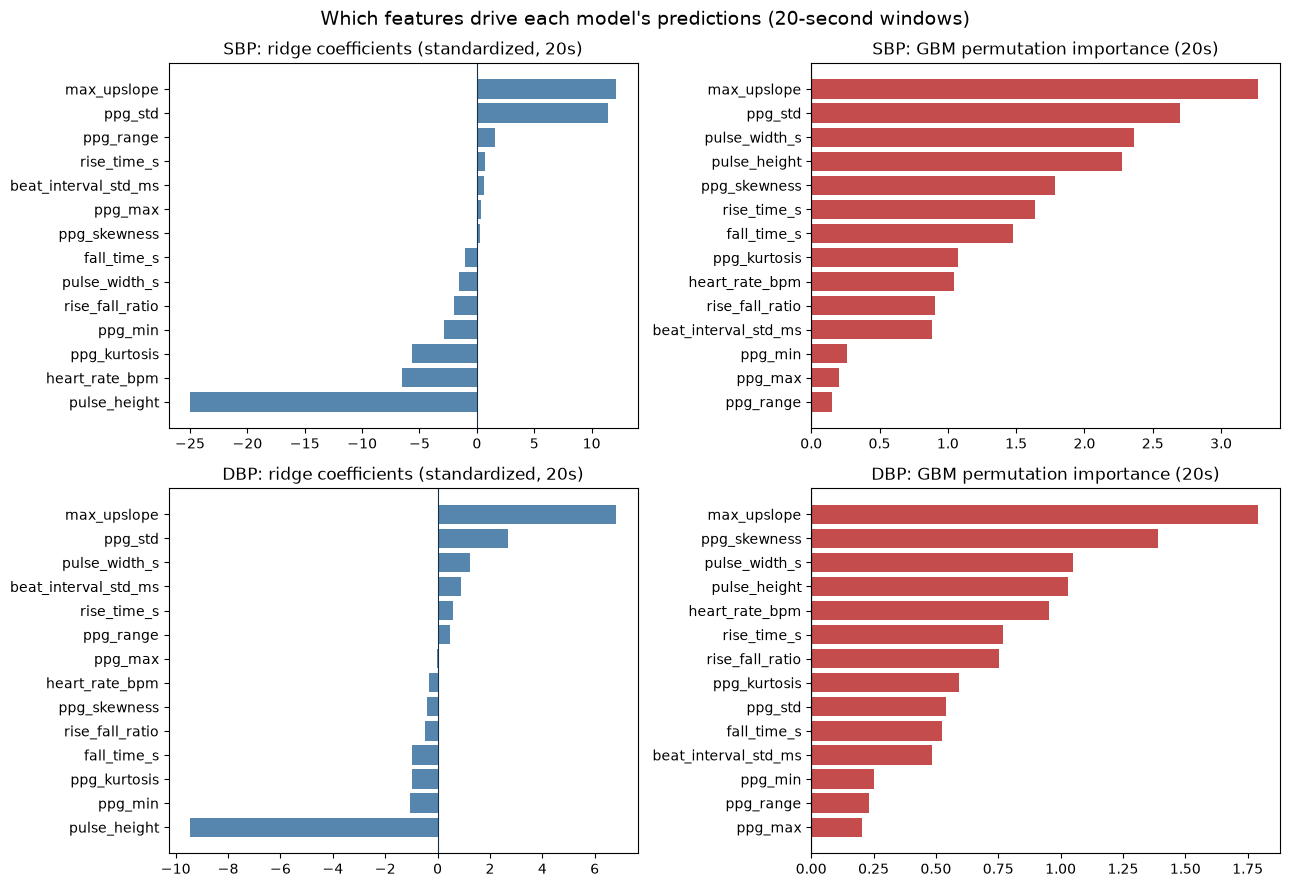

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for row, target in enumerate(TARGET_COLS):
    subset = importance[importance['target'] == target].set_index('feature')

    ax = axes[row, 0]
    ordered = subset.sort_values('coefficient')
    ax.barh(ordered.index, ordered['coefficient'], color='#5686ad')
    ax.set_title(f'{target.upper()}: ridge coefficients (standardized, 20s)')
    ax.axvline(0, color='#183047', linewidth=0.8)

    ax = axes[row, 1]
    ordered = subset.sort_values('importance_mean')
    ax.barh(ordered.index, ordered['importance_mean'], color='#c44c4c')
    ax.set_title(f'{target.upper()}: GBM permutation importance (20s)')
    ax.axvline(0, color='#183047', linewidth=0.8)

fig.suptitle('Which features drive each model\'s predictions (20-second windows)', fontsize=14)
fig.tight_layout()
fig.savefig(graphs_dir / 'feature_importance_20s.png', dpi=150)
plt.show()
plt.close(fig)

## Notes

- Same split logic, CV grids, and random seeds as `modeling.ipynb` — the only thing
  that changed is the input file (20-second windows instead of 5-second windows), so
  any difference in MAE/RMSE between the two notebooks reflects window length, not a
  methodology change.
- Fewer, longer windows means fewer total training rows but each row's features are
  averaged over more heartbeats, which could make the 14 features less noisy per row.